# A2C (Advantage Actor-Critic): blood delivery drone

## 1. Setup

In [1]:
import os
import sys
import random

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.distributions import Categorical
from collections import deque

# Run from the project root so that `environment/` can be imported.
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

from environment.custom_env import BloodDroneEnv, MASK_START, mask_scores

env = BloodDroneEnv()
STATE_SIZE = env.observation_space.shape[0]   # 43 numbers describe the drone and its surroundings
NUM_ACTIONS = env.action_space.n              # 9 actions
print("State size:", STATE_SIZE, "| Actions:", NUM_ACTIONS)


State size: 43 | Actions: 9


## 2. Helper functions

`make_net` builds a small neural network.

In [2]:
EPISODES = 500          # training episodes for every experiment
REWARD_SCALE = 0.1      # smaller rewards for training only (helps stability)


def make_net(inputs, hidden, outputs):
    """A small neural network: inputs -> hidden layers -> one score per action."""
    layers, size = [], inputs
    for h in hidden:
        layers += [nn.Linear(size, h), nn.ReLU()]
        size = h
    layers.append(nn.Linear(size, outputs))
    return nn.Sequential(*layers)


## 3. The A2C agent

`train_a2c` trains one agent for 500 episodes and returns the reward of every episode and the loss values.

In [3]:
def train_a2c(config, episodes=EPISODES):
    """Train one A2C agent. Returns the reward of every episode and the loss values."""
    random.seed(0); np.random.seed(0); torch.manual_seed(0)
    env = BloodDroneEnv(practice=0.8)   # the same training setting as training/a2c_training.py

    actor = make_net(STATE_SIZE, config["hidden"], NUM_ACTIONS)    # chooses actions
    critic = make_net(STATE_SIZE, config["hidden"], 1)             # estimates how good a state is
    optimizer = optim.Adam(list(actor.parameters()) + list(critic.parameters()), lr=config["lr"])
    rewards, losses = [], []

    for episode in range(episodes):
        state, _ = env.reset()
        done, total = False, 0.0

        while not done:
            log_probs, values, entropies, step_rewards = [], [], [], []

            # 1. Play up to n_steps steps.
            for _ in range(config["n_steps"]):
                obs = torch.tensor(state)
                dist = Categorical(logits=mask_scores(actor(obs), obs))
                action = dist.sample()
                state, reward, terminated, truncated, _ = env.step(action.item())
                done = terminated or truncated
                log_probs.append(dist.log_prob(action))
                values.append(critic(obs).squeeze())
                entropies.append(dist.entropy())
                step_rewards.append(reward * REWARD_SCALE)
                total += reward
                if done:
                    break

            # 2. Discounted returns, starting from the critic's guess if the episode is not over.
            g = 0.0 if done else critic(torch.tensor(state)).item()
            returns = []
            for r in reversed(step_rewards):
                g = r + config["gamma"] * g
                returns.insert(0, g)
            returns = torch.tensor(returns, dtype=torch.float32)

            # 3. Advantage = what really happened minus what the critic expected.
            values = torch.stack(values)
            advantage = returns - values.detach()
            actor_loss = -(torch.stack(log_probs) * advantage).mean()
            critic_loss = F.mse_loss(values, returns)
            entropy = torch.stack(entropies).mean()
            loss = actor_loss + config["value_coeff"] * critic_loss - config["entropy_coeff"] * entropy

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            losses.append(loss.item())

        rewards.append(total)

    return rewards, losses


## 4. The 10 experiments

Experiment 1 is the baseline. In each of the other nine experiments only one hyperparameter is changed.

In [4]:
a2c_configs = [
    {"name": "A2C-1", "lr": 0.0003, "gamma": 0.99, "value_coeff": 0.5, "entropy_coeff": 0.01, "hidden": (64, 64), "n_steps": 20},
    {"name": "A2C-2", "lr": 0.001, "gamma": 0.99, "value_coeff": 0.5, "entropy_coeff": 0.01, "hidden": (64, 64), "n_steps": 20},
    {"name": "A2C-3", "lr": 0.0001, "gamma": 0.99, "value_coeff": 0.5, "entropy_coeff": 0.01, "hidden": (64, 64), "n_steps": 20},
    {"name": "A2C-4", "lr": 0.0003, "gamma": 0.95, "value_coeff": 0.5, "entropy_coeff": 0.01, "hidden": (64, 64), "n_steps": 20},
    {"name": "A2C-5", "lr": 0.0003, "gamma": 0.999, "value_coeff": 0.5, "entropy_coeff": 0.01, "hidden": (64, 64), "n_steps": 20},
    {"name": "A2C-6", "lr": 0.0003, "gamma": 0.99, "value_coeff": 0.25, "entropy_coeff": 0.01, "hidden": (64, 64), "n_steps": 20},
    {"name": "A2C-7", "lr": 0.0003, "gamma": 0.99, "value_coeff": 0.75, "entropy_coeff": 0.01, "hidden": (64, 64), "n_steps": 20},
    {"name": "A2C-8", "lr": 0.0003, "gamma": 0.99, "value_coeff": 0.5, "entropy_coeff": 0.001, "hidden": (64, 64), "n_steps": 20},
    {"name": "A2C-9", "lr": 0.0003, "gamma": 0.99, "value_coeff": 0.5, "entropy_coeff": 0.02, "hidden": (64, 64), "n_steps": 20},
    {"name": "A2C-10", "lr": 0.0003, "gamma": 0.99, "value_coeff": 0.5, "entropy_coeff": 0.01, "hidden": (128, 128), "n_steps": 20},
]

## 5. Run the experiments

In [5]:
results = []      # one row per experiment
curves = {}       # reward of every episode, for the plots

for config in a2c_configs:
    rewards, losses = train_a2c(config)
    curves[config["name"]] = rewards
    results.append({
        "experiment": config["name"],
        "average reward": round(float(np.mean(rewards)), 1),
        "last 100": round(float(np.mean(rewards[-100:])), 1),
        "loss": round(float(np.mean(losses)), 3),
    })
    print(config["name"], "| average:", results[-1]["average reward"], "| last 100:", results[-1]["last 100"], "| loss:", results[-1]["loss"])

A2C-1 | average: -103.3 | last 100: -87.7 | loss: 2.238


A2C-2 | average: -106.2 | last 100: -92.8 | loss: 1.61


A2C-3 | average: -113.4 | last 100: -112.3 | loss: 3.03


A2C-4 | average: -115.5 | last 100: -117.6 | loss: 2.504


A2C-5 | average: -112.8 | last 100: -113.3 | loss: 1.488


A2C-6 | average: -106.1 | last 100: -100.9 | loss: 0.78


A2C-7 | average: -106.6 | last 100: -95.0 | loss: 3.487


A2C-8 | average: -105.2 | last 100: -87.2 | loss: 2.319


A2C-9 | average: -109.5 | last 100: -103.0 | loss: 1.915


A2C-10 | average: -99.1 | last 100: -84.8 | loss: 1.947


## 6. Results

In [6]:
print(f"{'experiment':<14}{'average reward':>16}{'last 100':>12}{'loss':>10}")
for row in results:
    print(f"{row['experiment']:<14}{row['average reward']:>16}{row['last 100']:>12}{row['loss']:>10}")

experiment      average reward    last 100      loss
A2C-1                   -103.3       -87.7     2.238
A2C-2                   -106.2       -92.8      1.61
A2C-3                   -113.4      -112.3      3.03
A2C-4                   -115.5      -117.6     2.504
A2C-5                   -112.8      -113.3     1.488
A2C-6                   -106.1      -100.9      0.78
A2C-7                   -106.6       -95.0     3.487
A2C-8                   -105.2       -87.2     2.319
A2C-9                   -109.5      -103.0     1.915
A2C-10                   -99.1       -84.8     1.947


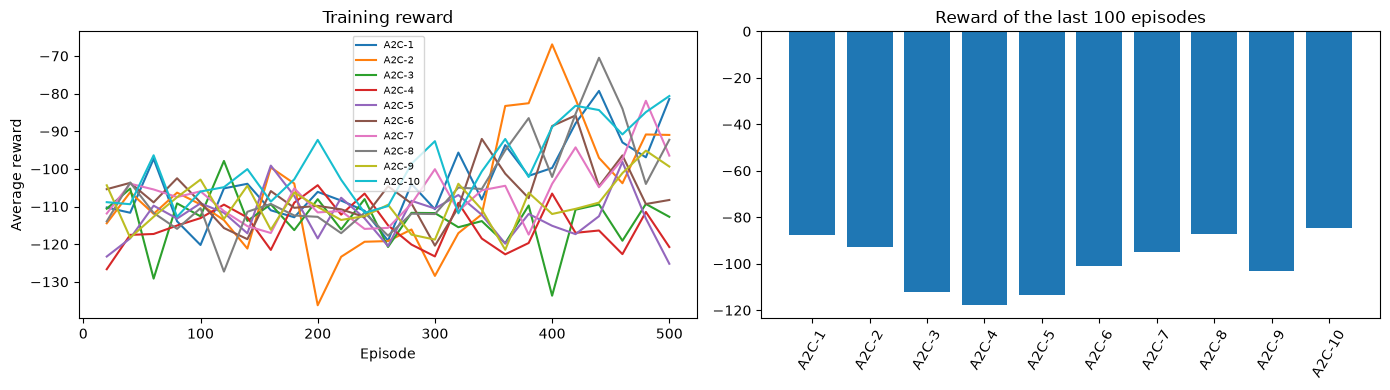

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# learning curves (average of every 20 episodes)
for name, rewards in curves.items():
    smooth = [np.mean(rewards[i:i + 20]) for i in range(0, len(rewards), 20)]
    axes[0].plot(range(20, len(rewards) + 1, 20), smooth, label=name)
axes[0].set_title("Training reward")
axes[0].set_xlabel("Episode")
axes[0].set_ylabel("Average reward")
axes[0].legend(fontsize=7)

# reward of the last 100 episodes of every experiment (what the agent learned)
axes[1].bar([row["experiment"] for row in results], [row["last 100"] for row in results])
axes[1].set_title("Reward of the last 100 episodes")
axes[1].tick_params(axis="x", rotation=60)

plt.tight_layout()
plt.show()

## 7. Best hyperparameters

The best experiment is the one with the highest average reward in its last 100 episodes, because that shows what the agent has learned (the early episodes are mostly random exploration). These values are the ones to use in `training/a2c_training.py`.

In [8]:
# the best experiment has the highest reward in its last 100 episodes (smaller loss breaks a tie)
best = sorted(results, key=lambda row: (-row["last 100"], row["loss"]))[0]
best_config = next(c for c in a2c_configs if c["name"] == best["experiment"])

print("Best experiment:", best["experiment"])
print("Last 100 episodes:", best["last 100"], "| average:", best["average reward"], "| loss:", best["loss"])
print("Best hyperparameters:")
for key, value in best_config.items():
    if key != "name":
        print("  ", key, "=", value)

Best experiment: A2C-10
Last 100 episodes: -84.8 | average: -99.1 | loss: 1.947
Best hyperparameters:
   lr = 0.0003
   gamma = 0.99
   value_coeff = 0.5
   entropy_coeff = 0.01
   hidden = (128, 128)
   n_steps = 20
